In [69]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [58]:
df = pd.read_csv('data\\sonar.all-data.csv')

In [59]:
df.head()

,Freq_1,Freq_2,Freq_3,Freq_4,Freq_5,Freq_6,Freq_7,Freq_8,Freq_9,Freq_10,...,Freq_52,Freq_53,Freq_54,Freq_55,Freq_56,Freq_57,Freq_58,Freq_59,Freq_60,Label
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


## Исследование данных

**ЗАДАНИЕ: Нарисуйте тепловую карту heatmap, показывающую корреляцию между откликами на различных частотах.**

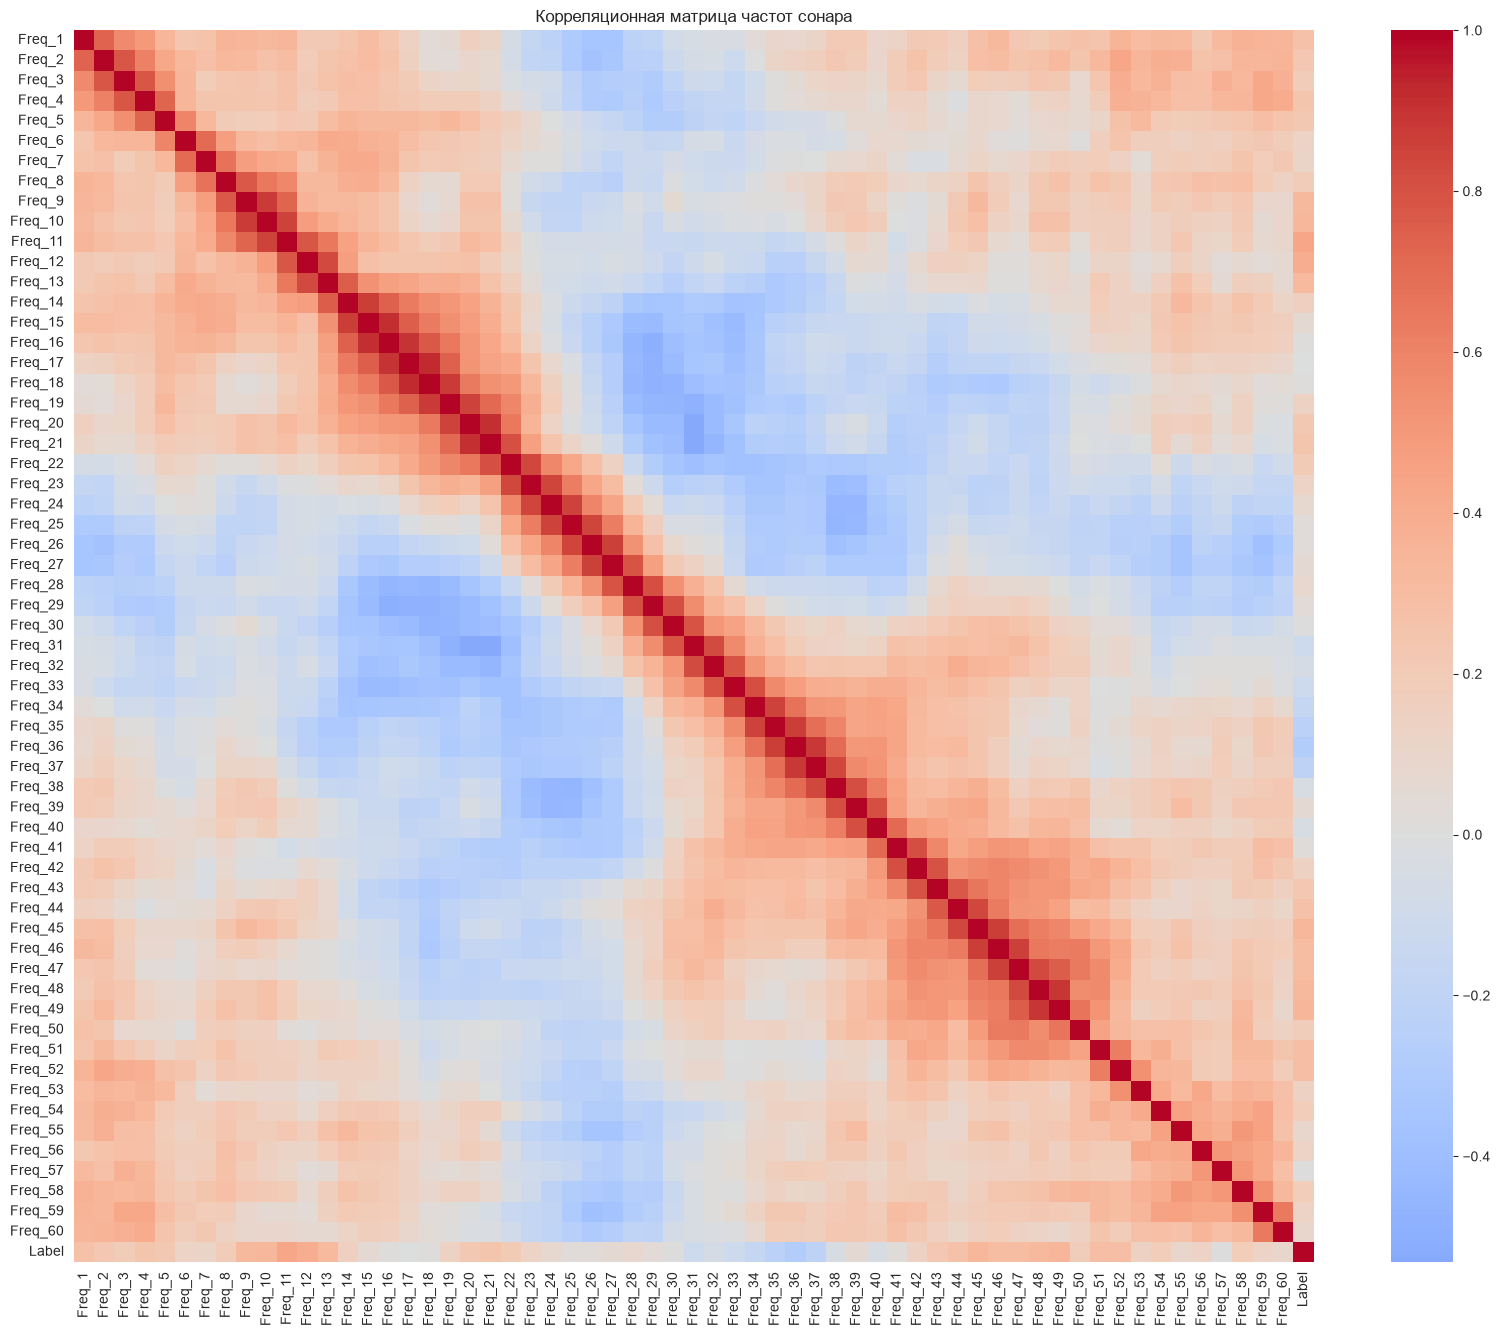

In [60]:
df_encoded = df.copy()
df_encoded['Label'] = df_encoded['Label'].map({'M': 1, 'R': 0})

plt.figure(figsize=(20, 16))
sns.heatmap(df_encoded.corr(), cmap='coolwarm', center=0)
plt.title('Корреляционная матрица частот сонара')
plt.show()

**ЗАДАНИЕ: Какие 5 частот лучше всего коррелируют с целевой переменной?**

*Замечание: Вы можете пометить целевую переменную с помощью значений 0 и 1.*

*Замечание 2: мы ищем **абсолютные** значения корреляции.*

In [61]:
correlations = df_encoded.corr()['Label'].abs().sort_values(ascending=False)

top_5_freq = correlations.drop('Label').head(5)
print("Топ-5 частот с наибольшей абсолютной корреляцией:")
print(top_5_freq)

Топ-5 частот с наибольшей абсолютной корреляцией:
Freq_11    0.432855
Freq_12    0.392245
Freq_49    0.351312
Freq_10    0.341142
Freq_45    0.339406
Name: Label, dtype: float64


## Разбиение на обучающий и тестовый наборы данных

Здесь мы будем использовать кросс-валидацию на 90% данных, и затем оценим результаты работы нашей модели на тестовом наборе данных в 10%.

**ЗАДАНИЕ: Разделите данные на признаки и целевую переменную, а затем разбейте все данные на обучающий и тестовый наборы данных, в отношении 90% и 10%.**

In [63]:
from sklearn.model_selection import train_test_split

X = df.drop('Label', axis=1)
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (187, 60)
Размер тестовой выборки: (21, 60)


**ЗАДАНИЕ: Создайте объект PipeLine, в котором будет StandardScaler и модель KNN**

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

print(pipe)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


**ЗАДАНИЕ: С помощью пайплайна выполните поиск по сетке для различных значений k, и выведите наилучшие параметры.**

In [65]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'knn__n_neighbors': list(range(1, 30))
}

grid = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring='accuracy',
    verbose=1
)

grid.fit(X_train, y_train)

print(f"Лучшее значение k: {grid.best_params_}")
print(f"Лучшая точность: {grid.best_score_:.4f}")

Fitting 5 folds for each of 29 candidates, totalling 145 fits
Лучшее значение k: {'knn__n_neighbors': 1}
Лучшая точность: 0.8454


**(СЛОЖНОЕ) ЗАДАНИЕ: Используя словарь .cv_results_, попробуйте нарисовать график средних тестовых оценок (mean_test_score) для каждого значения K.**

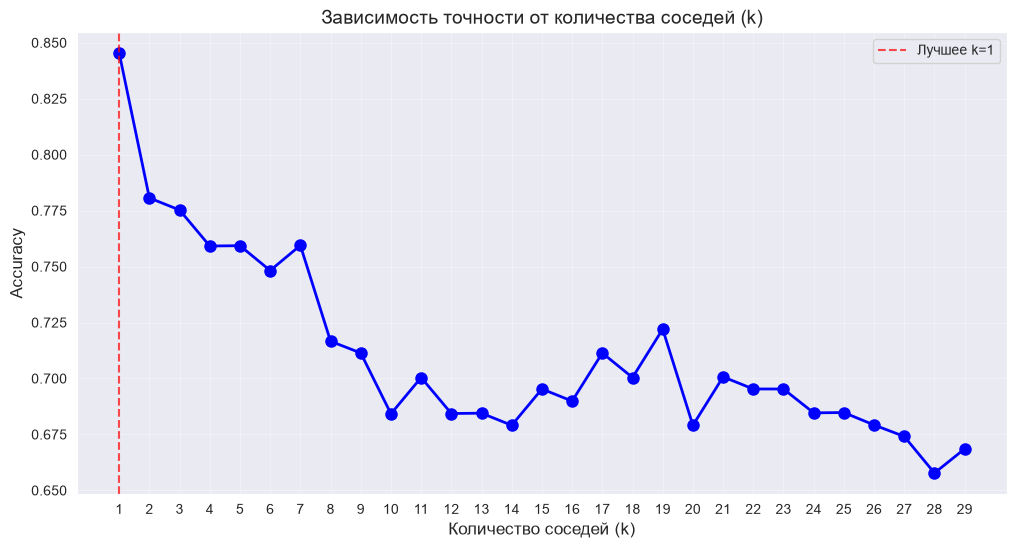

In [67]:
mean_test_scores = grid.cv_results_['mean_test_score']
k_values = range(1, 30)

plt.figure(figsize=(12, 6))
plt.plot(k_values, mean_test_scores, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Количество соседей (k)', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Зависимость точности от количества соседей (k)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.xticks(k_values)

best_k = grid.best_params_['knn__n_neighbors']
best_score = grid.best_score_
plt.axvline(x=best_k, color='r', linestyle='--', alpha=0.7,
            label=f'Лучшее k={best_k}')
plt.legend()
plt.show()

### Финальная оценка модели

**ЗАДАНИЕ: используя объект grid classifier с предыдущего шага, создайте финальный отчёт "classification report" и матрицу "confusion matrix".**

Точность на тестовой выборке: 0.9048

Classification Report:
              precision    recall  f1-score   support

           M       0.92      0.92      0.92        13
           R       0.88      0.88      0.88         8

    accuracy                           0.90        21
   macro avg       0.90      0.90      0.90        21
weighted avg       0.90      0.90      0.90        21


Confusion Matrix:
[[12  1]
 [ 1  7]]


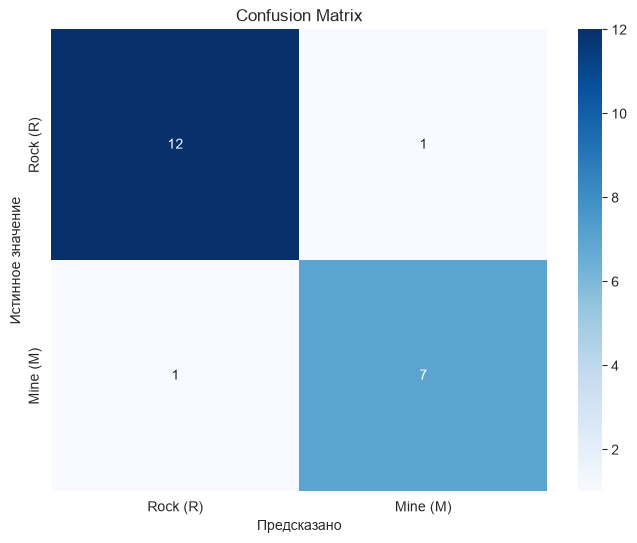

In [68]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = grid.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Точность на тестовой выборке: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rock (R)', 'Mine (M)'],
            yticklabels=['Rock (R)', 'Mine (M)'])
plt.xlabel('Предсказано')
plt.ylabel('Истинное значение')
plt.title('Confusion Matrix')
plt.show()